# 00 — PTB-XL Sample Waveforms (`[11, 13, 19, 92, 42]`)

Quick visual inspection of five individual 12-lead PTB-XL ECG recordings (`100 Hz`, `10 s`, `1,000` samples per lead) at dataset indices **`11`, `13`, `19`, `92`, and `42`**:

1. **Metadata & SCP-ECG Summary** for the five selected records.
2. **Full 12-Lead Waveform Plots** (`6 × 2` grid, all `10 s`) for each sample.
3. **Cross-Sample Lineplots** comparing Lead II and Lead V2 (`0–5 s` zoom) side by side.

In [1]:
import ast
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import wfdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({"figure.dpi": 120, "savefig.bbox": "tight"})

_cwd = Path.cwd().resolve()
for _candidate in [_cwd, _cwd.parent, _cwd.parent.parent]:
    if (_candidate / "ptbxl" / "data" / "ptbxl_database.csv").exists():
        REPO_ROOT = _candidate
        break
else:
    raise FileNotFoundError(f"Could not locate ptbxl/data/ptbxl_database.csv from {_cwd}")

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

DATA_DIR = REPO_ROOT / "ptbxl" / "data"
LEADS = ["I", "II", "III", "aVR", "aVL", "aVF", "V1", "V2", "V3", "V4", "V5", "V6"]
SAMPLE_INDICES = [11, 13, 19, 92, 42]

df_sub = pd.read_csv(DATA_DIR / "ptbxl_database.csv").iloc[SAMPLE_INDICES].copy()
df_sub.insert(0, "sample_idx", SAMPLE_INDICES)

signals = {}
meta_rows = []
for _, row in df_sub.iterrows():
    idx = int(row["sample_idx"])
    sig, _ = wfdb.rdsamp(str(DATA_DIR / row["filename_lr"]))
    signals[idx] = np.nan_to_num(sig).astype(np.float32)  # (1000, 12)
    meta_rows.append({
        "sample_idx": idx,
        "ecg_id": int(row["ecg_id"]),
        "patient_id": int(row["patient_id"]),
        "age": row["age"],
        "sex": "Female" if row["sex"] == 1 else "Male",
        "strat_fold": int(row["strat_fold"]),
        "scp_codes": row["scp_codes"],
        "report": str(row["report"])[:80],
    })

meta_df = pd.DataFrame(meta_rows).set_index("sample_idx")
display(meta_df)

,ecg_id,patient_id,age,sex,strat_fold,scp_codes,report
sample_idx,,,,,,,
11,12,11031,43.0,Female,8,"{'NORM': 80.0, 'SBRAD': 0.0}",sinusbradykardie sonst normales ekg
13,14,12925,19.0,Female,7,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
19,20,13619,56.0,Male,9,"{'AFLT': 100.0, 'ABQRS': 0.0}",supraventrikulÄre ersatzsystole(n) interponier...
92,93,10029,47.0,Male,10,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg
42,43,11315,25.0,Female,8,"{'NORM': 100.0, 'SR': 0.0}",sinusrhythmus normales ekg


## 1. Full 12-Lead Waveform Plots (`10 s @ 100 Hz`)

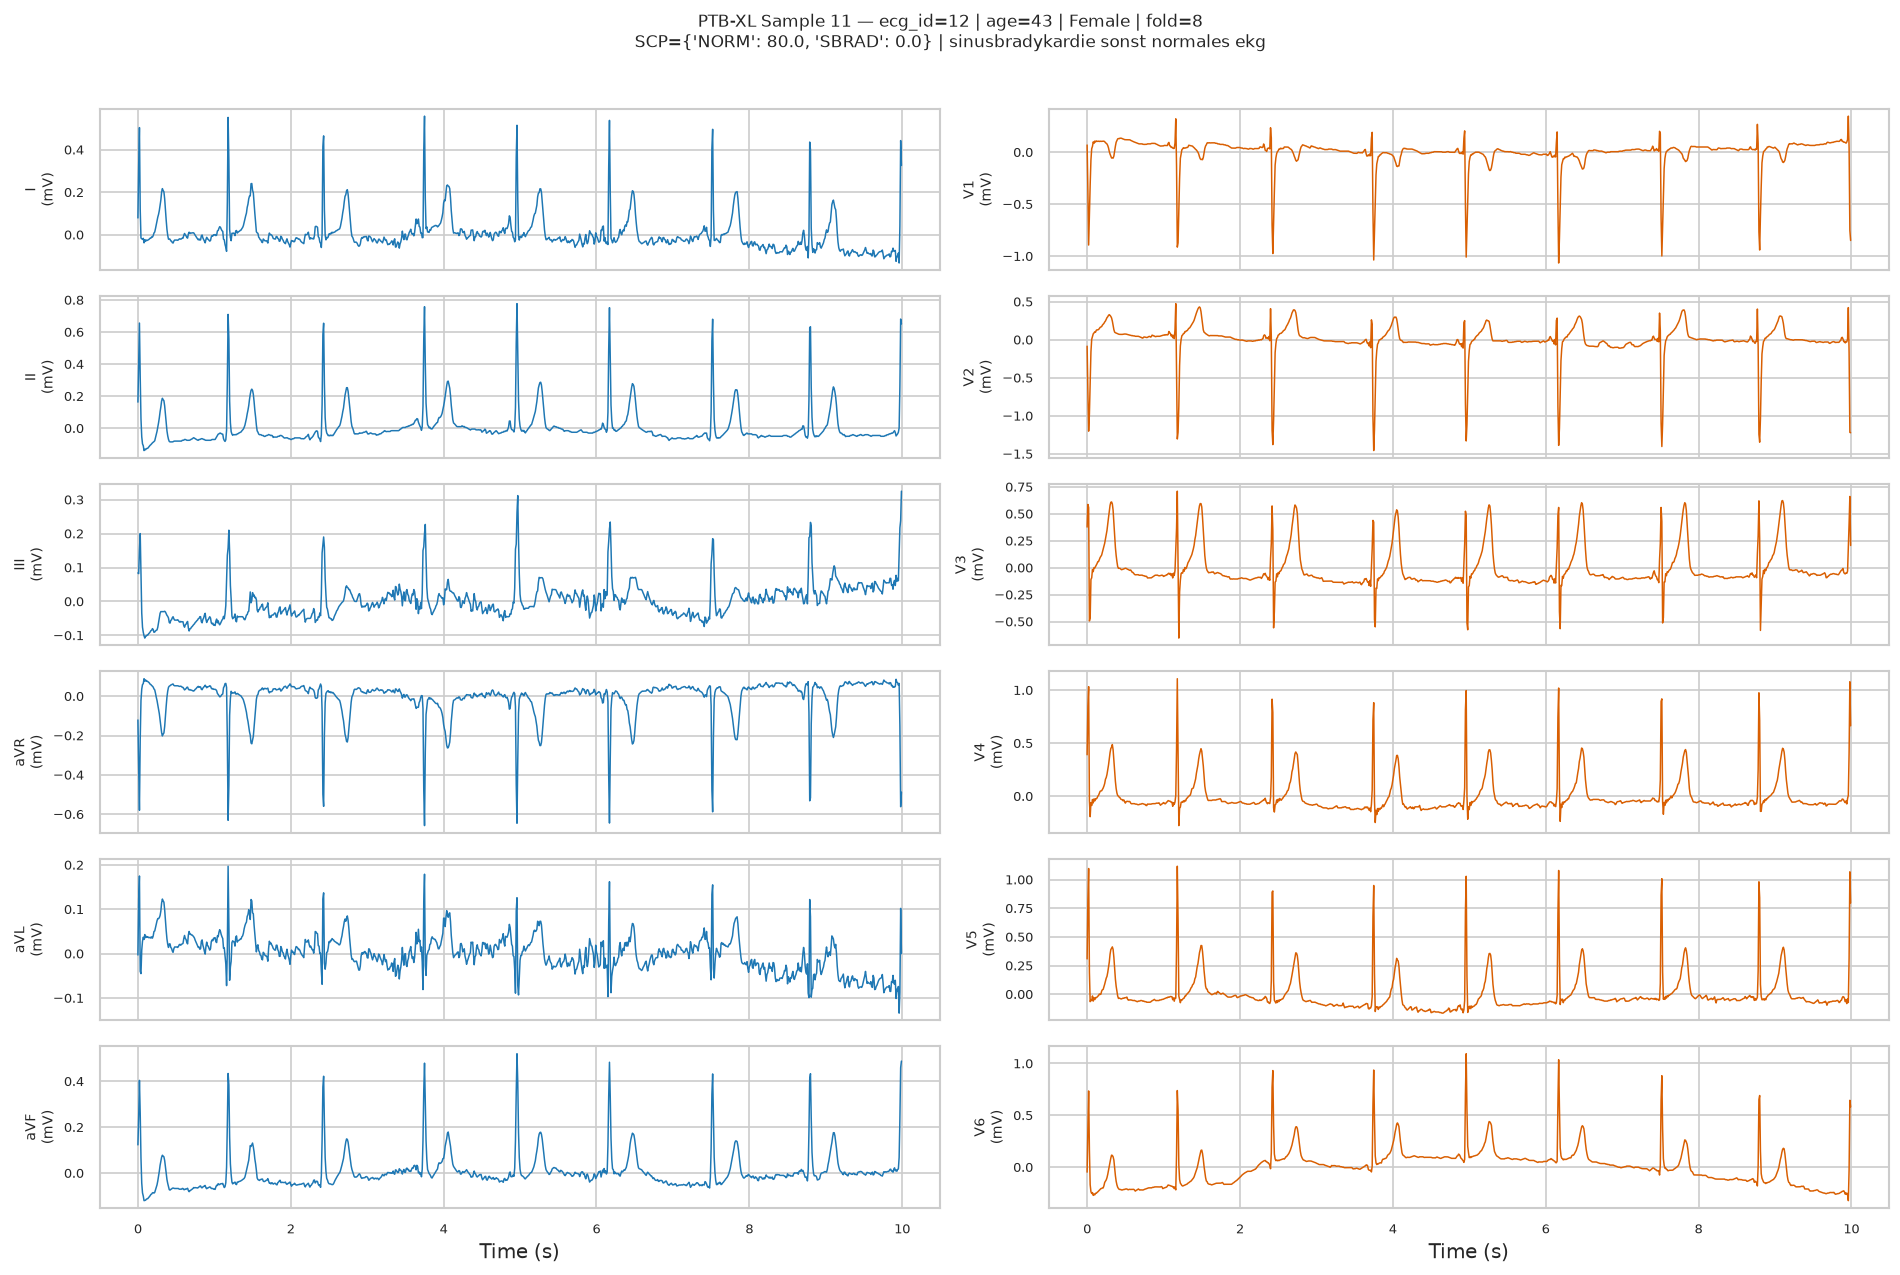

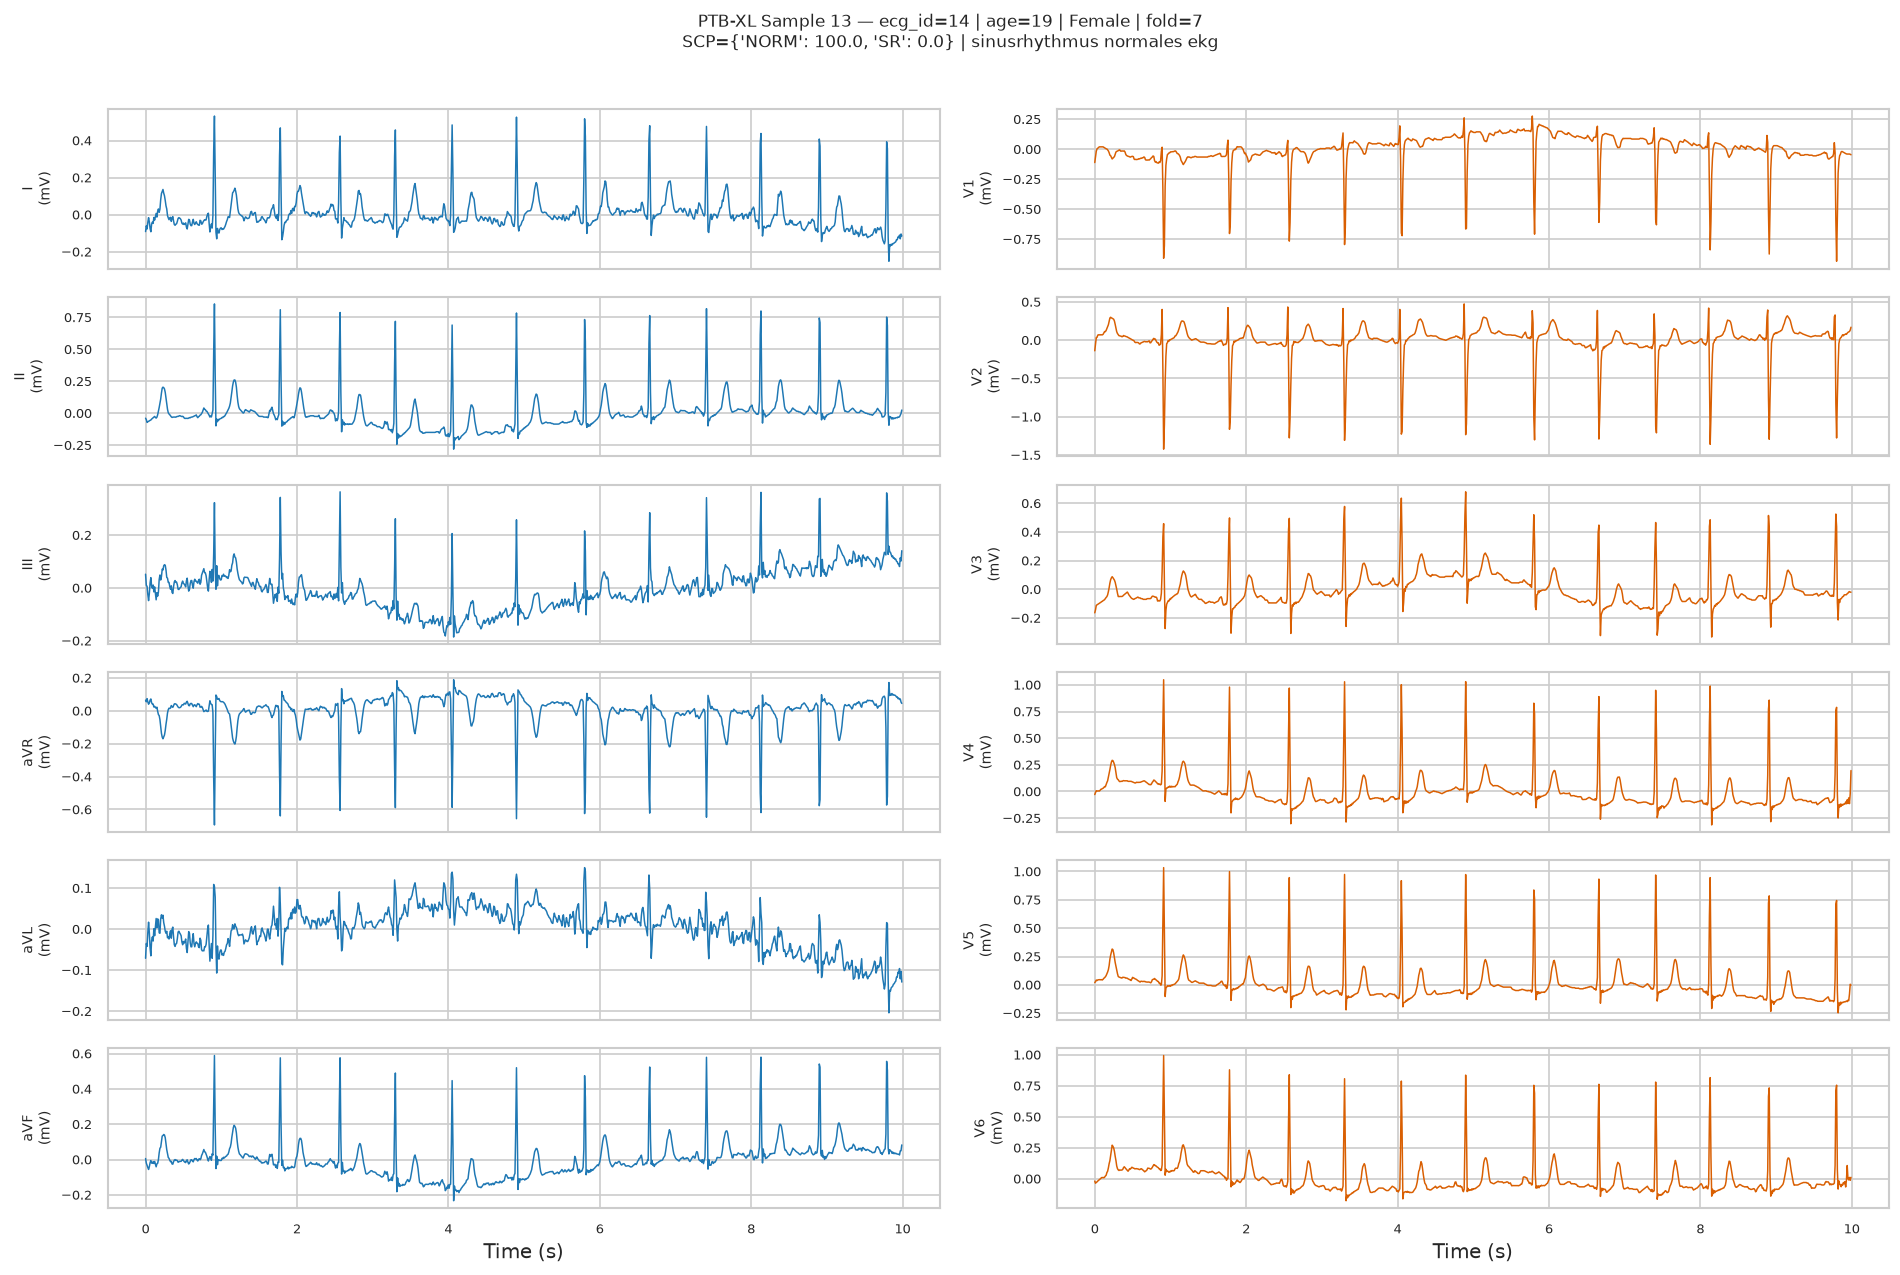

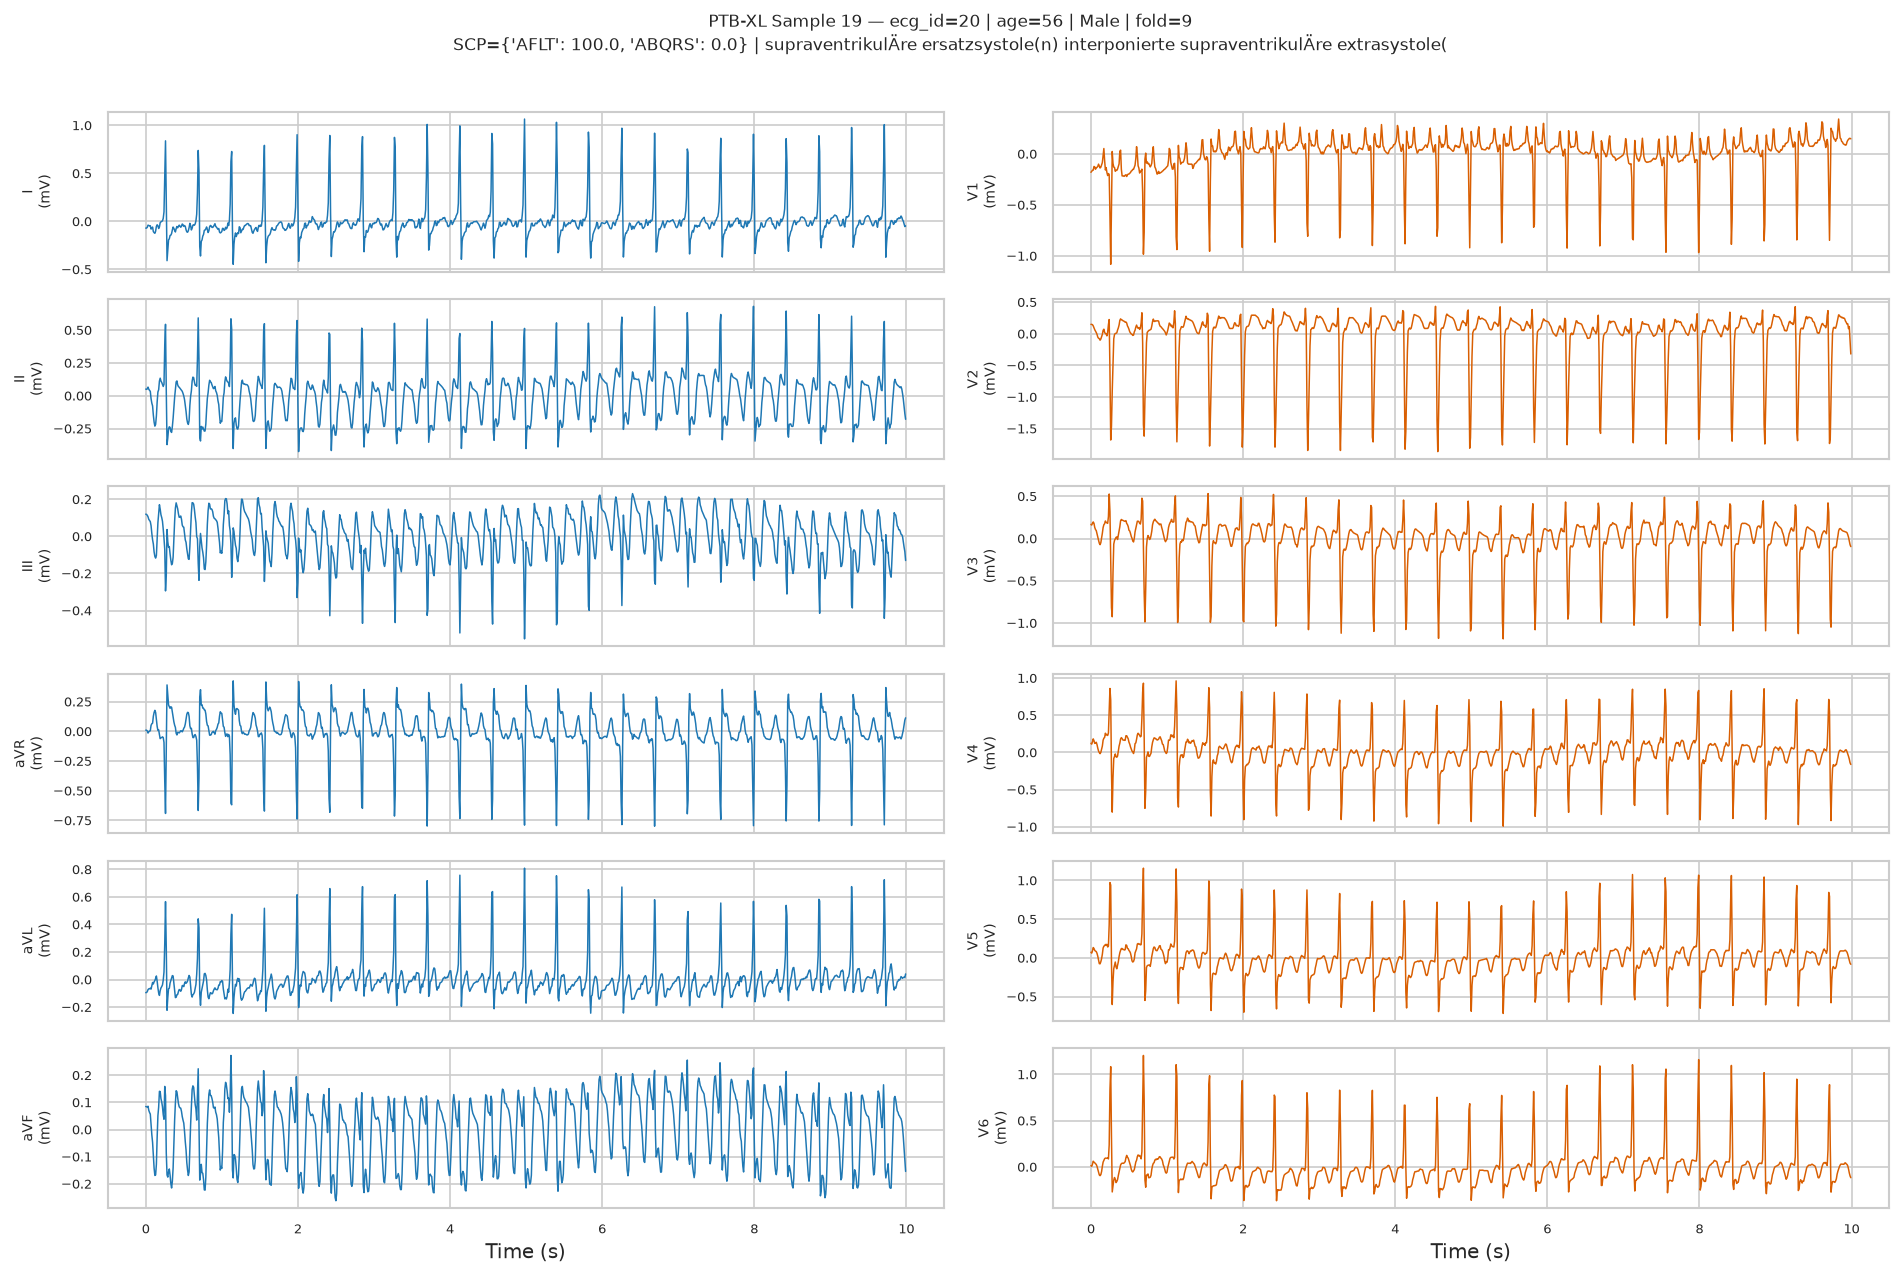

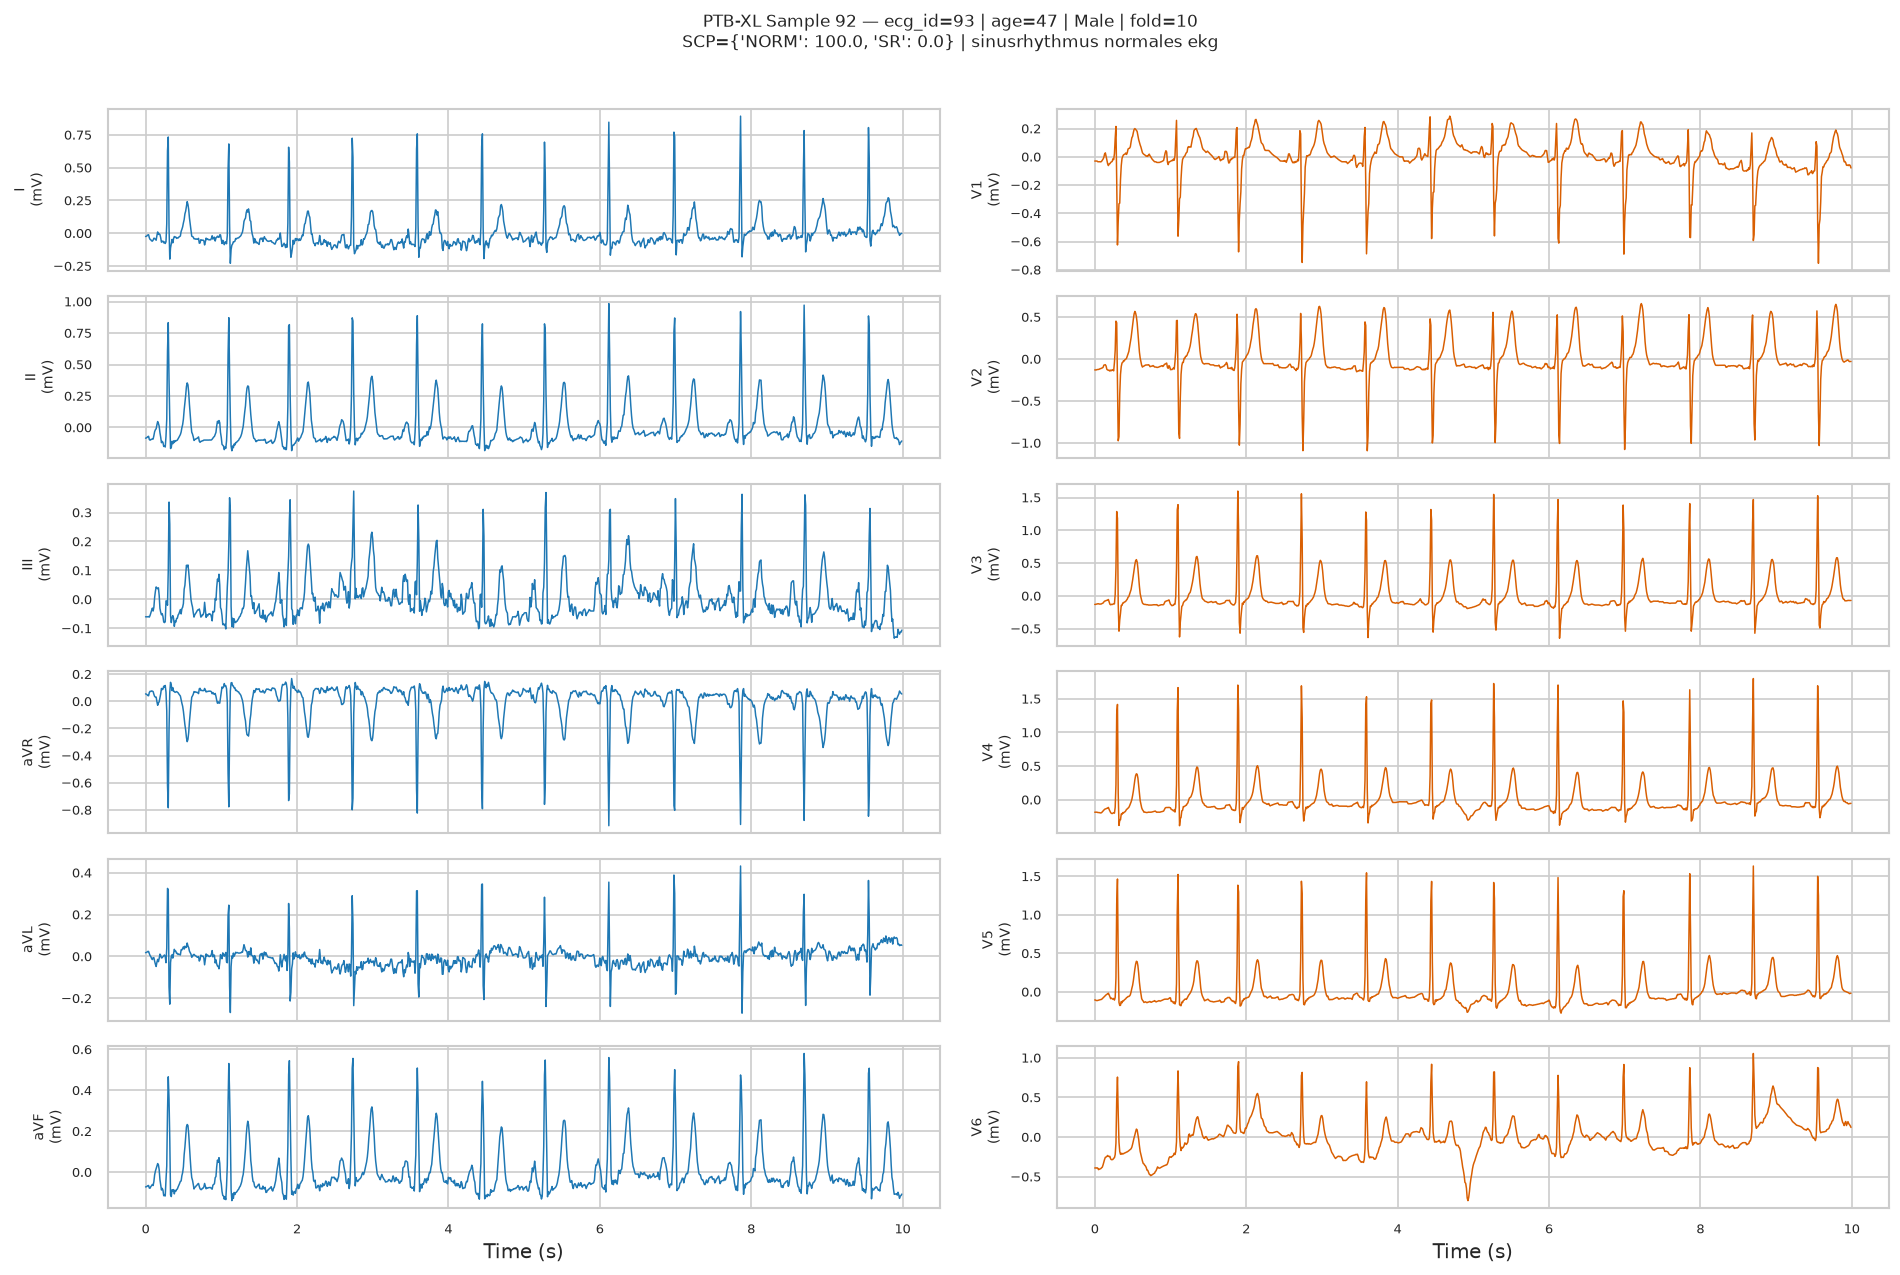

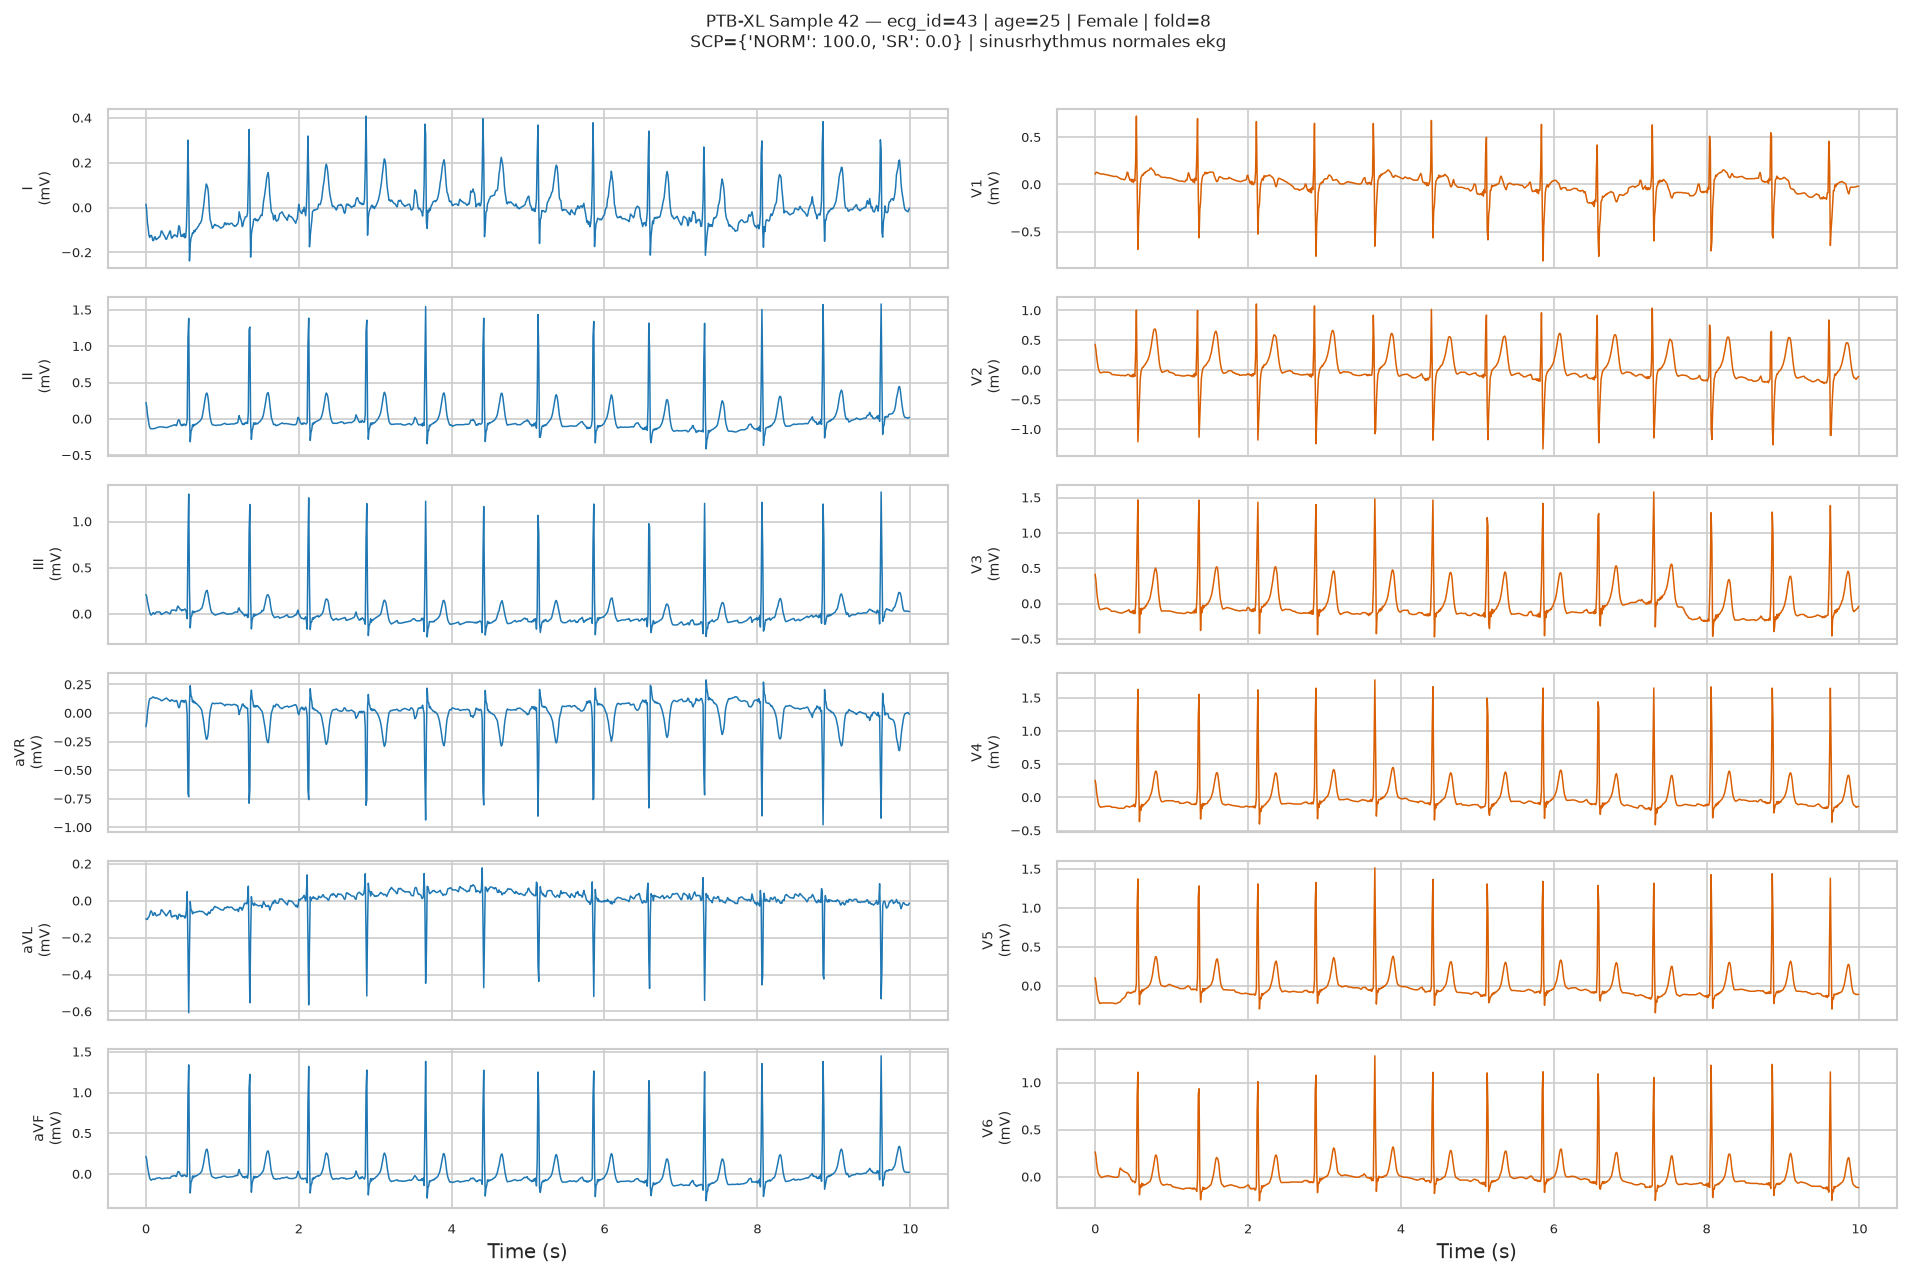

In [2]:
t_full = np.arange(1000) / 100.0

for idx in SAMPLE_INDICES:
    sig = signals[idx]
    row = meta_df.loc[idx]
    fig, axes = plt.subplots(6, 2, figsize=(16, 10.5), sharex=True)
    for j, lname in enumerate(LEADS):
        ax = axes[j % 6, j // 6]
        ax.plot(t_full, sig[:, j], color="#1f78b4" if j < 6 else "#d95f02", lw=0.9)
        ax.set_ylabel(f"{lname}\n(mV)", fontsize=8.5)
        ax.tick_params(labelsize=7.5)
    axes[5, 0].set_xlabel("Time (s)")
    axes[5, 1].set_xlabel("Time (s)")
    fig.suptitle(
        f"PTB-XL Sample {idx} — ecg_id={row["ecg_id"]} | age={row["age"]:.0f} | {row["sex"]} | fold={row["strat_fold"]}\n"
        f"SCP={row["scp_codes"]} | {row["report"]}",
        y=1.01, fontsize=10.2,
    )
    plt.tight_layout()
    plt.show()

## 2. Side-by-Side Lineplot Comparison (`0–5 s` Zoom: Lead II & Lead V2)

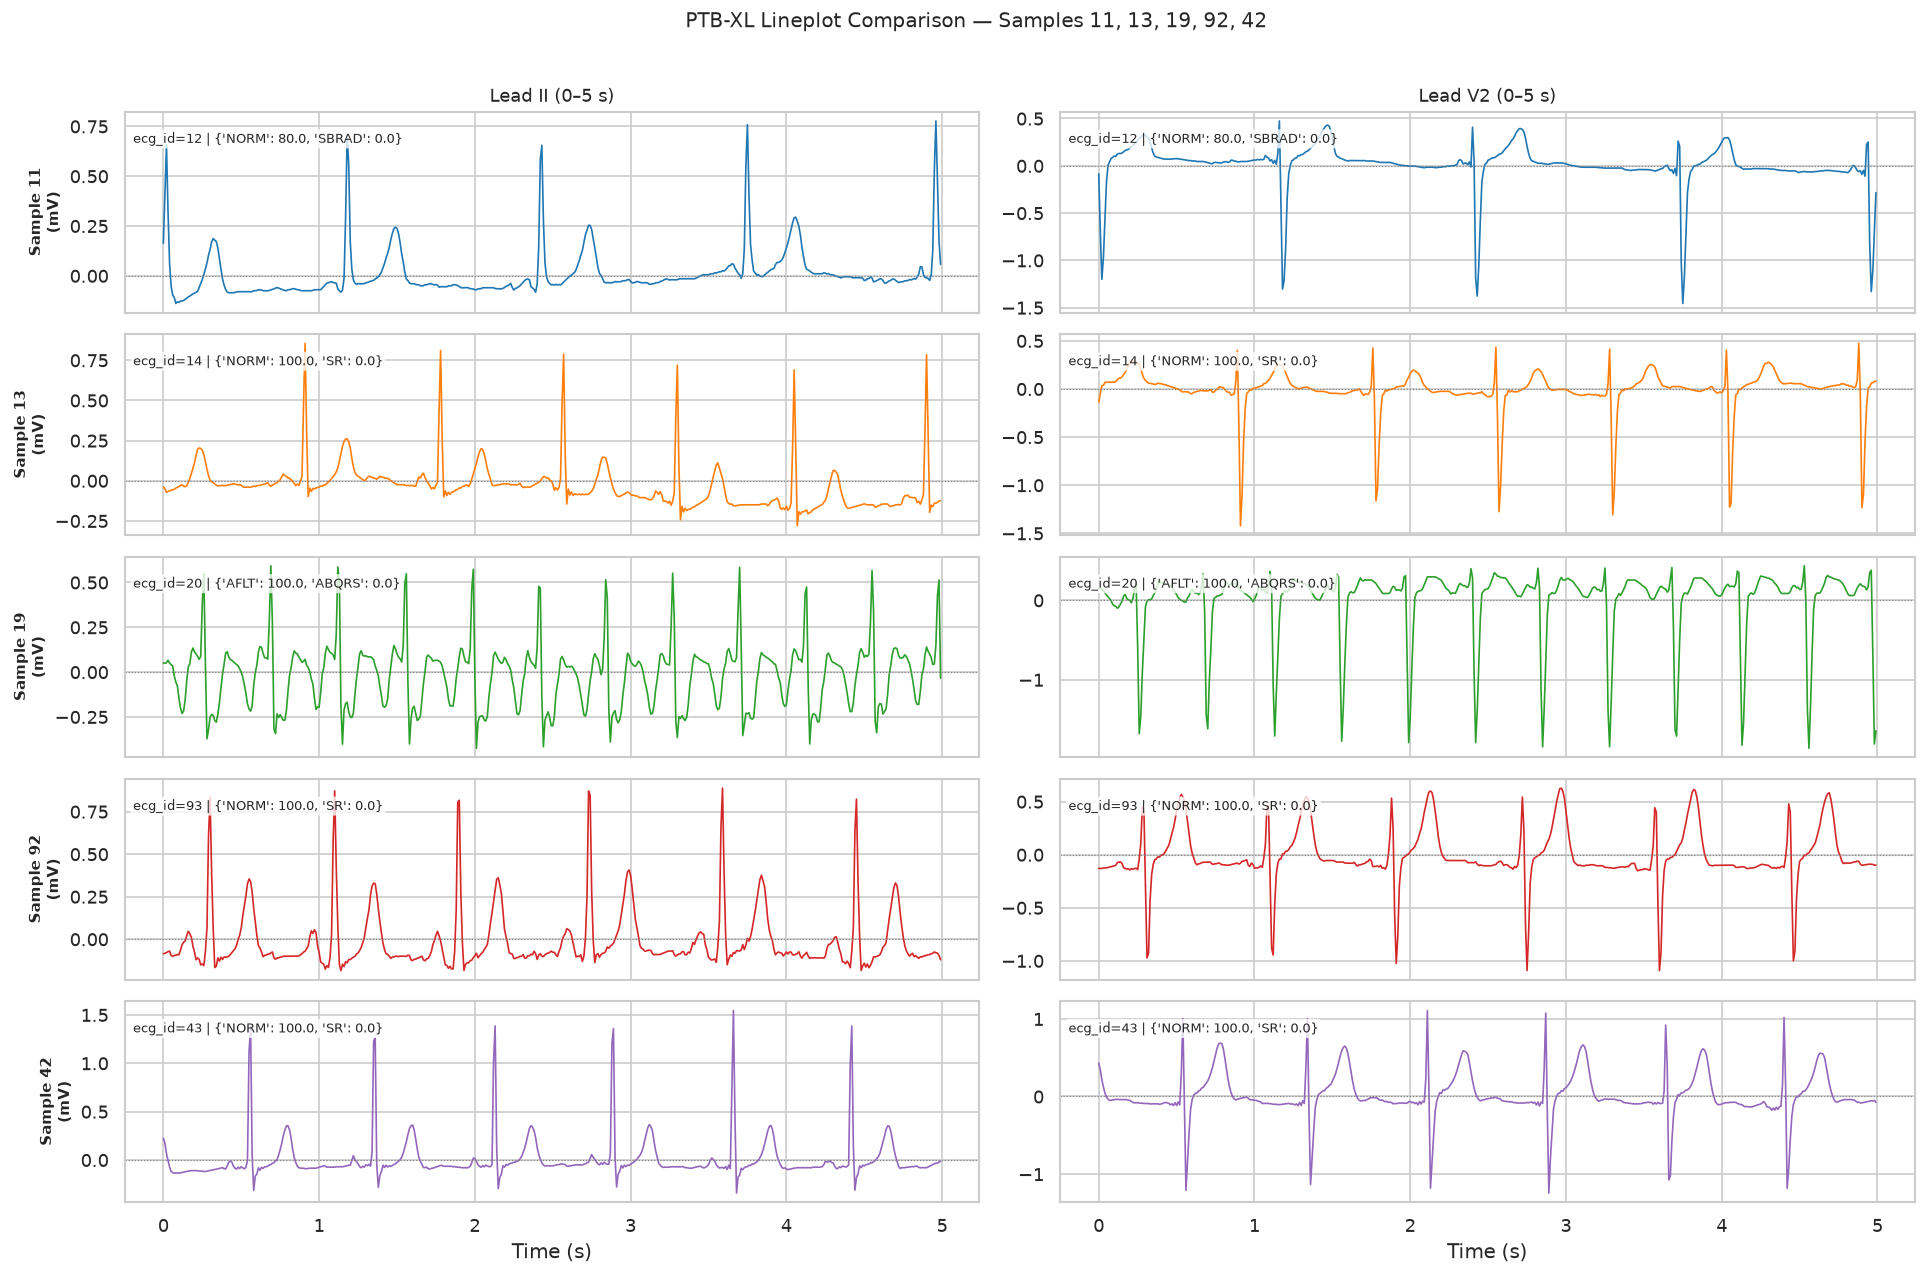

In [3]:
T_ZOOM = 500  # 5.0 seconds @ 100 Hz
t_zoom = np.arange(T_ZOOM) / 100.0
colors = sns.color_palette("tab10", n_colors=len(SAMPLE_INDICES))

fig, axes = plt.subplots(len(SAMPLE_INDICES), 2, figsize=(16, 10.5), sharex=True)
for r_i, (idx, col) in enumerate(zip(SAMPLE_INDICES, colors)):
    sig = signals[idx]
    row = meta_df.loc[idx]
    for c_i, (l_idx, lname) in enumerate([(1, "II"), (7, "V2")]):
        ax = axes[r_i, c_i]
        ax.plot(t_zoom, sig[:T_ZOOM, l_idx], color=col, lw=1.0)
        ax.axhline(0, color="gray", ls=":", lw=0.7)
        if c_i == 0:
            ax.set_ylabel(f"Sample {idx}\n(mV)", fontsize=9, fontweight="bold")
        if r_i == 0:
            ax.set_title(f"Lead {lname} (0–5 s)", fontsize=10.5)
        ax.text(
            0.01, 0.90,
            f"ecg_id={row["ecg_id"]} | {row["scp_codes"]}",
            transform=ax.transAxes, fontsize=7.5, va="top",
            bbox=dict(boxstyle="round,pad=0.2", facecolor="white", alpha=0.78, edgecolor="none"),
        )

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")
fig.suptitle("PTB-XL Lineplot Comparison — Samples 11, 13, 19, 92, 42", y=1.01, fontsize=12)
plt.tight_layout()
plt.show()